In [1]:
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif


### Loading the dataset


In [2]:
df = pd.read_csv('./data/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### EDA

In [3]:
display(df.shape)
display(HTML("<hr>"))

df.info()

(918, 12)

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
display(df.describe())
display(HTML("<hr>"))

print (df.isnull().sum())
display(HTML("<hr>"))

display(df.duplicated().sum())
display(HTML("<hr>"))

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


np.int64(0)

In [5]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [6]:
df.columns = (
    df.columns
    .str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True) 
    .str.lower() 
)
df.columns

Index(['age', 'sex', 'chest_pain_type', 'resting_bp', 'cholesterol',
       'fasting_bs', 'resting_ecg', 'max_hr', 'exercise_angina', 'oldpeak',
       'st_slope', 'heart_disease'],
      dtype='str')

heart_disease
1    508
0    410
Name: count, dtype: int64
heart_disease
1    0.55
0    0.45
Name: proportion, dtype: float64


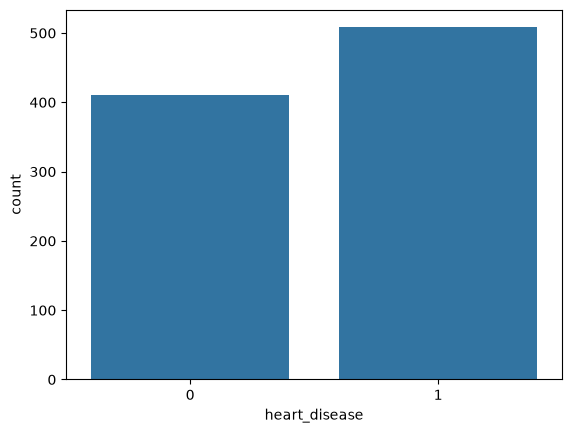

In [7]:
print(df["heart_disease"].value_counts())
print(df["heart_disease"].value_counts(normalize=True).round(2))
sns.countplot(x="heart_disease", data=df); plt.show()

About 55% of patients have heart disease and 45% don’t, so the classes are fairly balanced. Accuracy is a fair metric, but I’ll report AUC and recall too.



In [8]:
(df[["resting_bp", "cholesterol"]] == 0).sum()

resting_bp       1
cholesterol    172
dtype: int64

172 cholesterol values and 1 resting BP value are 0, which isn't physically possible, so they're hidden missing values. I'll convert them to NaN and fill with the median, fitted on the training set only

In [9]:
cols = ["resting_bp", "cholesterol"]
df[cols] = df[cols].replace(0, np.nan)

(df[cols] == 0).sum()

resting_bp     0
cholesterol    0
dtype: int64

In [10]:
df[cols].isna().sum()

resting_bp       1
cholesterol    172
dtype: int64

In [11]:
numerical_col = df.select_dtypes(include='number').columns.tolist()
numerical_col.remove('heart_disease')
categorical_col = df.select_dtypes(exclude='number').columns.tolist()

numerical_col.remove('fasting_bs')
categorical_col.append('fasting_bs')
print(numerical_col, "\n", categorical_col)

['age', 'resting_bp', 'cholesterol', 'max_hr', 'oldpeak'] 
 ['sex', 'chest_pain_type', 'resting_ecg', 'exercise_angina', 'st_slope', 'fasting_bs']


#### Numerical features analysis

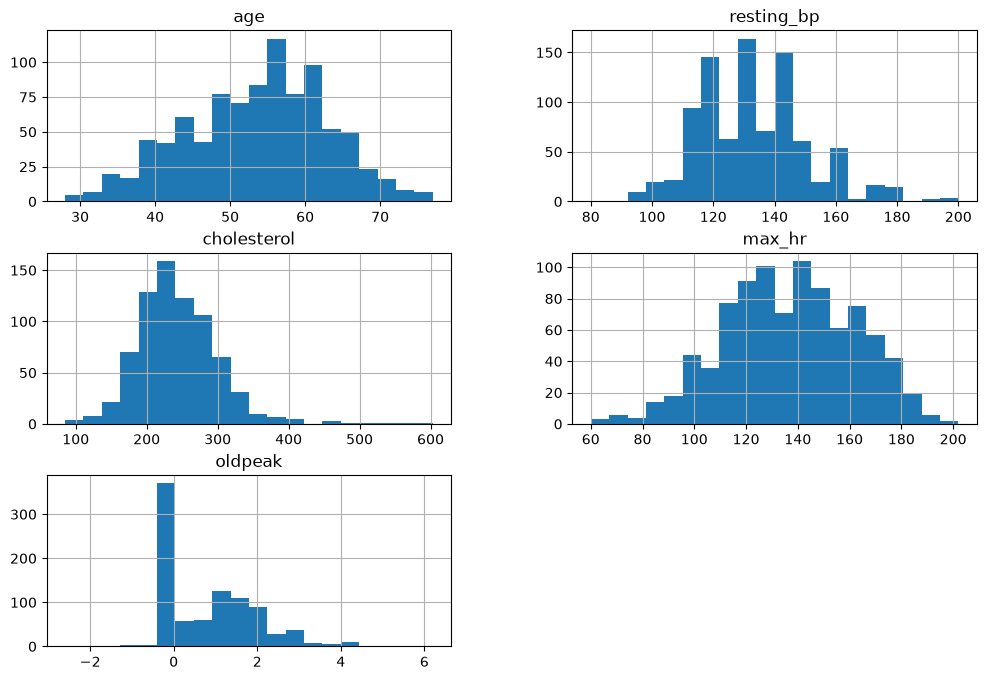

                 age  resting_bp  cholesterol  max_hr  oldpeak
heart_disease                                                 
0              50.55      130.18       238.77  148.15     0.41
1              55.90      134.45       251.06  127.66     1.27


In [12]:
df[numerical_col].hist(bins=20, figsize=(12, 8))
plt.show()

print(df.groupby("heart_disease")[numerical_col].mean().round(2))

- Disease group: lower max heart rate (127.66 vs 148.15), higher oldpeak (1.27 vs 0.41), older (around 56 vs around 51).
- Resting BP and cholesterol differ only slightly.
- Cholesterol and oldpeak are right-skewed.

Patients with heart disease tend to be older and have higher resting blood pressure and cholesterol levels on average. However, these differences are relatively small.

max_hr is noticeably lower, while oldpeak is higher among patients with heart disease. These features may be useful for predicting heart disease.

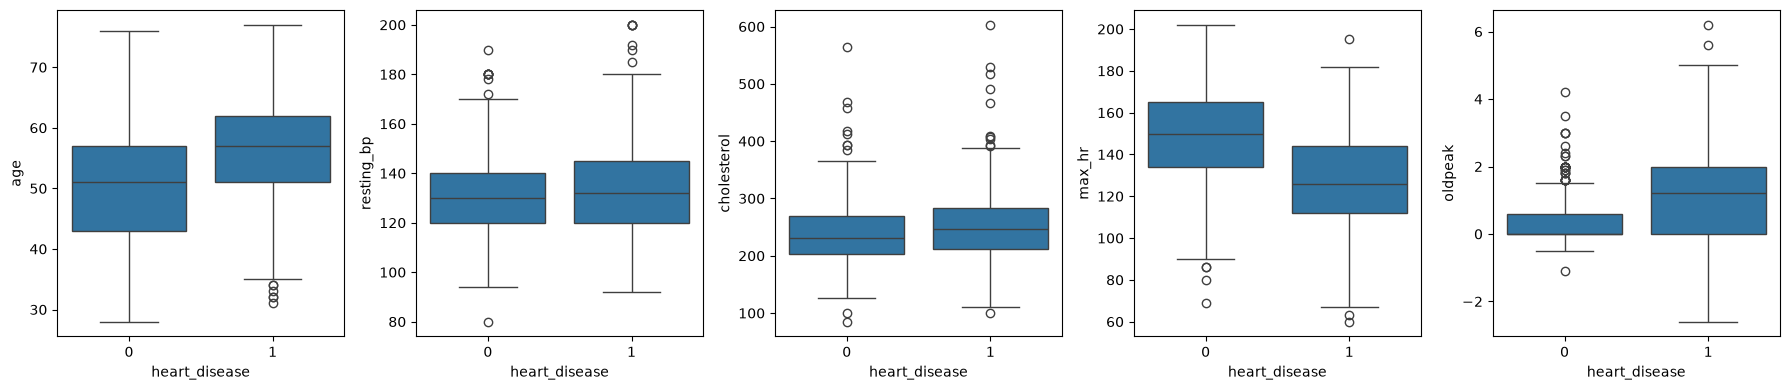

In [13]:

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, numerical_col):
    sns.boxplot(x="heart_disease", y=c, data=df, ax=ax)
plt.tight_layout()
plt.show()

The boxplots reveal some potential outliers.
- Max heart rate and oldpeak separate the classes best.
- Resting BP and cholesterol overlap heavily.
- Outliers in cholesterol, resting BP and oldpeak, a few negative oldpeak values.

#### Categorical features analysis

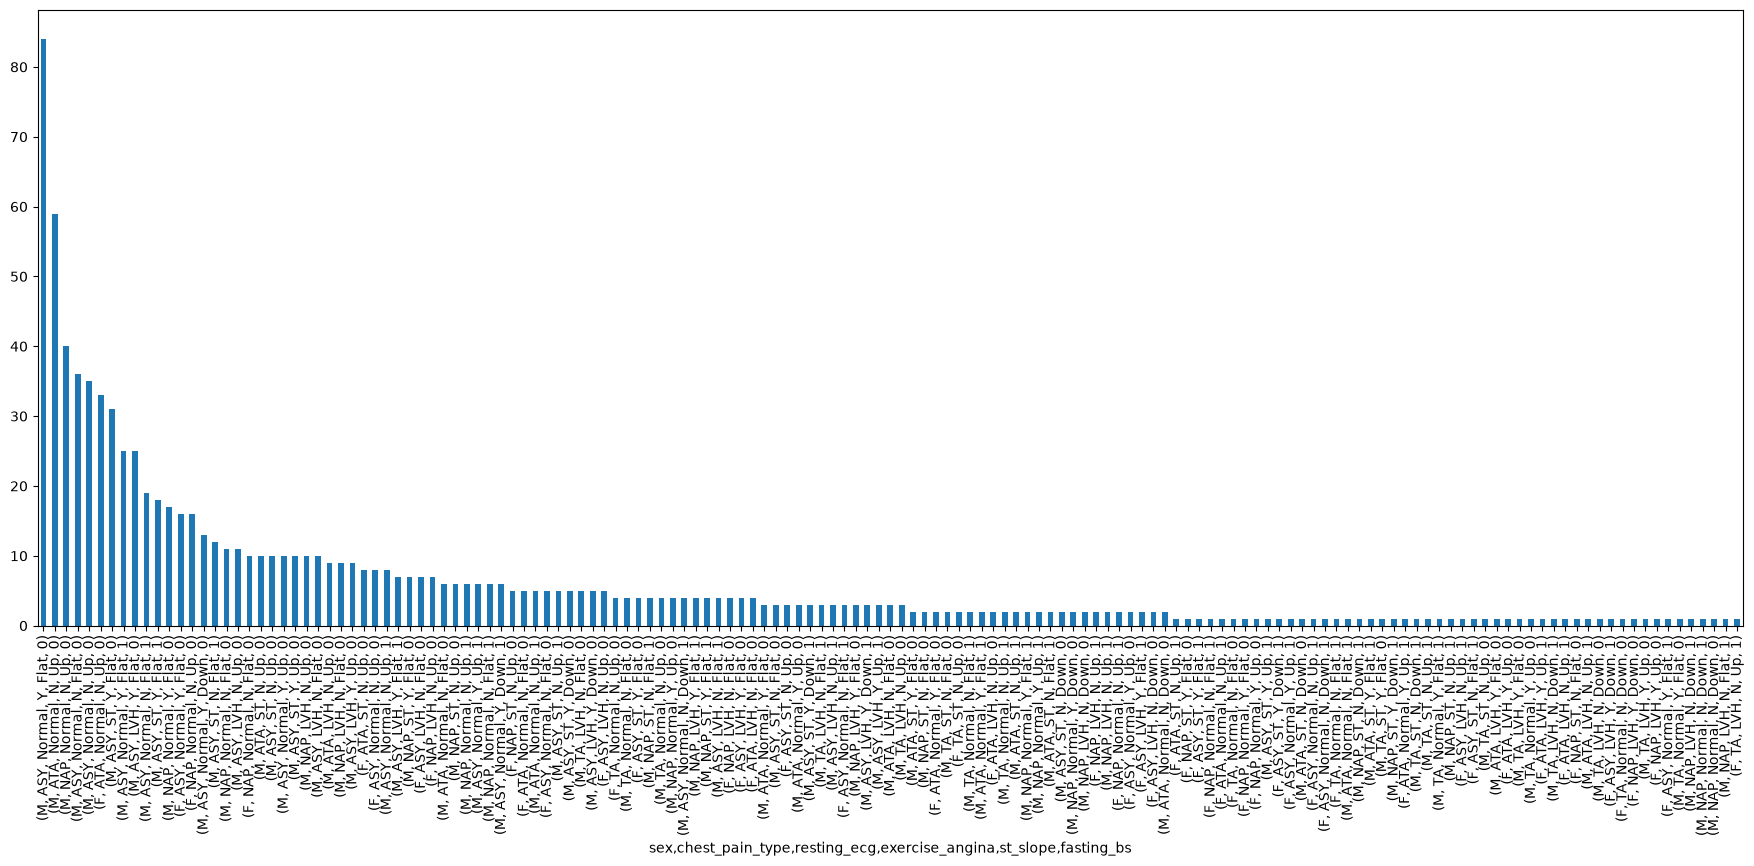

In [14]:
df[categorical_col].value_counts().plot(kind="bar", figsize=(22, 8))
plt.show()

In [15]:
for col in categorical_col:
    print(f"\n{col}")
    display(pd.crosstab(
        df[col],
        df['heart_disease'],
        normalize='index'
    ).round(3))
    print("--------------------------")


sex


heart_disease,0,1
sex,,
F,0.741,0.259
M,0.368,0.632


--------------------------

chest_pain_type


heart_disease,0,1
chest_pain_type,,
ASY,0.210,0.790
ATA,0.861,0.139
NAP,0.645,0.355
TA,0.565,0.435


--------------------------

resting_ecg


heart_disease,0,1
resting_ecg,,
LVH,0.436,0.564
Normal,0.484,0.516
ST,0.343,0.657


... (3 outputs left out)

heart_disease,0,1
st_slope,,
Down,0.222,0.778
Flat,0.172,0.828
Up,0.803,0.197


--------------------------

fasting_bs


heart_disease,0,1
fasting_bs,,
0,0.520,0.480
1,0.206,0.794


--------------------------



- Exercise angina: 85% disease vs 35% without.
- Chest pain ASY: 79% vs 14% for ATA.
- ST slope Up: 20%; Flat and Down: about 80%.

- Fasting blood sugar = 1: 79% vs 48%.
- Men 63% vs women 26%, but only about 21% of patients are women. Which is an imbalance.
- Resting ECG differs little.


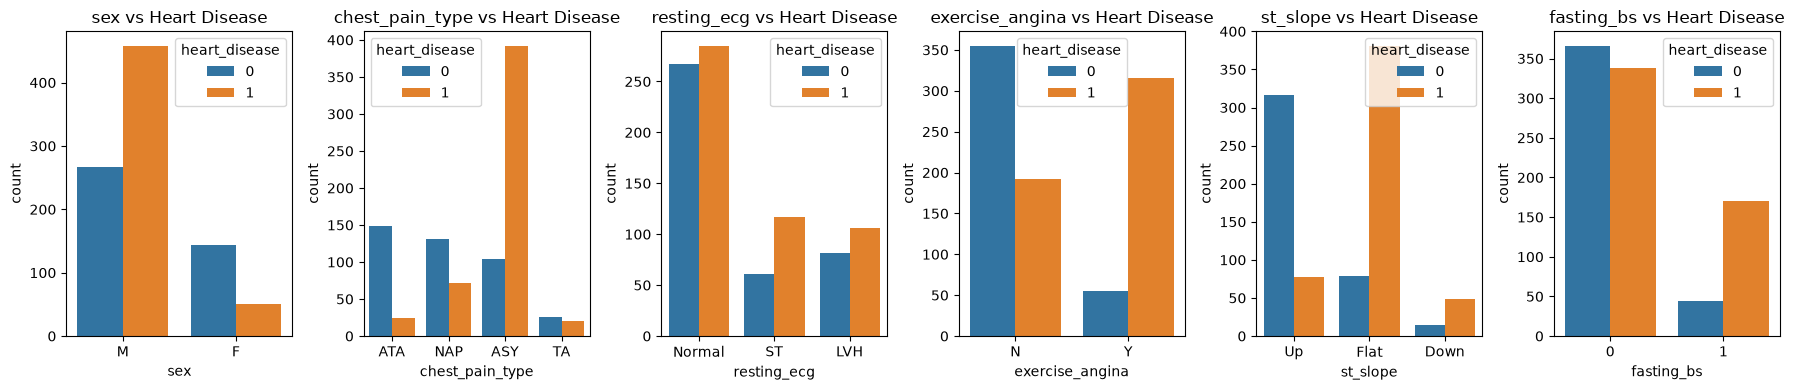

In [16]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for col, ax in zip(categorical_col, axes.flatten()):
    sns.countplot(
        data=df,
        x=col,
        hue='heart_disease',
        ax=ax
    )
    ax.set_title(f'{col} vs Heart Disease')

plt.tight_layout()
plt.show()

ChestPainType, ExerciseAngina, and ST_Slope show the strongest differences in heart disease proportions across categories. Sex and FastingBS also show noticeable differences, while RestingECG shows relatively smaller differences.

These features may be useful for predicting heart disease.

#### Correlations

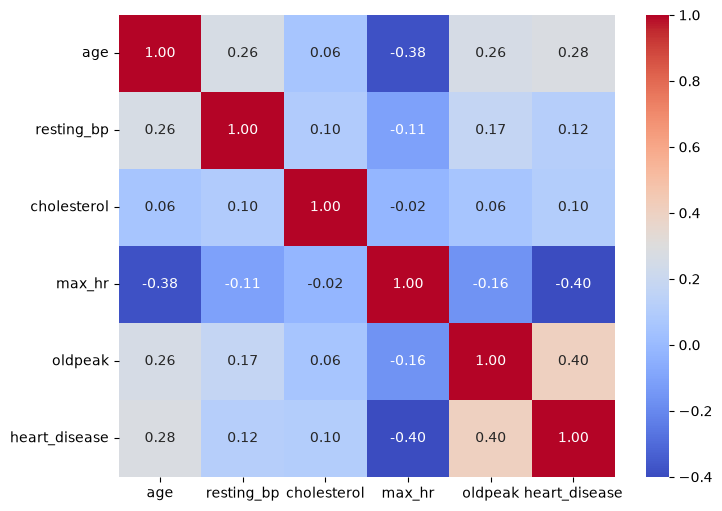

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_col + ["heart_disease"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

- Strongest links with heart disease: max_hr (-0.40), oldpeak (0.40), age (0.28).
- Weak: resting_bp (0.12) and cholesterol (0.10).

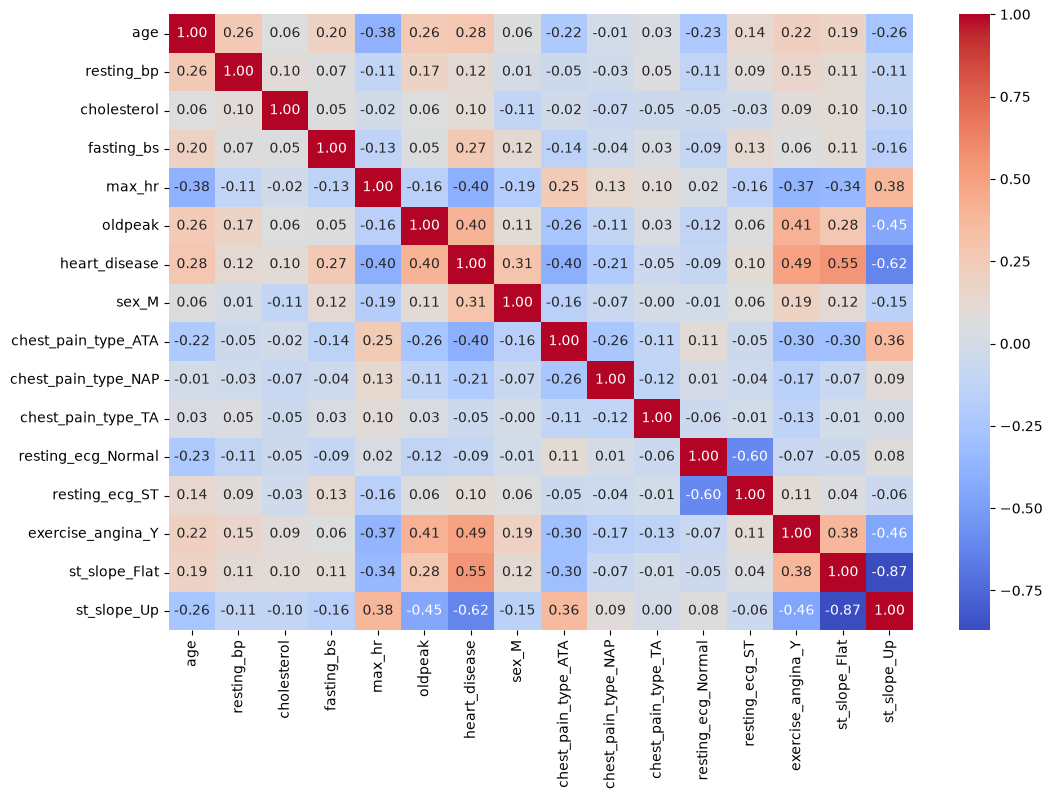

In [18]:
df_encoded = pd.get_dummies(df, drop_first=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    df_encoded.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.show()

#### Feature importance


st_slope_Up            0.227
st_slope_Flat          0.175
exercise_angina_Y      0.128
oldpeak                0.125
max_hr                 0.079
chest_pain_type_ATA    0.069
cholesterol            0.065
age                    0.047
sex_M                  0.047
fasting_bs             0.036
chest_pain_type_TA     0.018
resting_bp             0.012
chest_pain_type_NAP    0.012
resting_ecg_Normal     0.000
resting_ecg_ST         0.000
dtype: float64


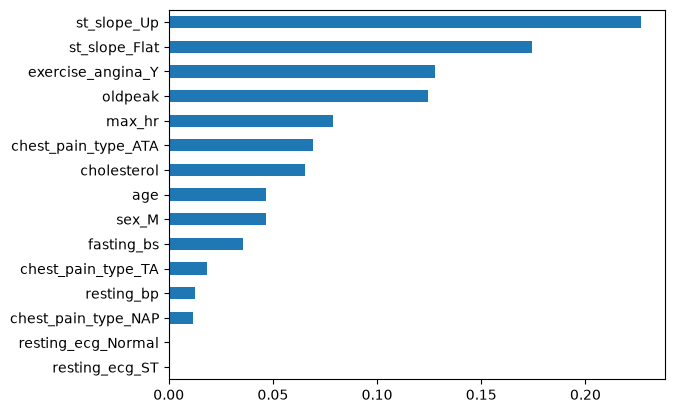

In [19]:
X = pd.get_dummies(df.drop(columns="heart_disease"), drop_first=True).astype(float)
X = X.fillna(X.median())          # only for this EDA step
mi = pd.Series(
    mutual_info_classif(X, df["heart_disease"], random_state=42),
    index=X.columns,
).sort_values(ascending=False)
print(mi.round(3))
mi.plot(kind="barh")
plt.gca().invert_yaxis()
plt.show()

- Most informative: st_slope (Up 0.227, Flat 0.175), exercise_angina_Y (0.128), oldpeak (0.125), max_hr (0.079).
- Least informative: resting_ecg (0.000), resting_bp (0.012).

### Data preparation

In [22]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

(len(df_full_train), len(df_train), len(df_val), len(df_test))

(734, 550, 184, 184)